In [1]:
import copy
import importlib.util
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Running on device:", device)

PyTorch version: 2.11.0+cpu
Running on device: cpu


In [2]:
def load_digit_splits(seed=SEED):
    digits = load_digits()
    images = torch.tensor(digits.images, dtype=torch.float32) / 16.0
    labels = torch.tensor(digits.target, dtype=torch.long)
    indices = np.arange(len(labels))
    train_idx, temp_idx = train_test_split(
        indices, train_size=0.6, stratify=digits.target, random_state=seed
    )
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=0.5, stratify=digits.target[temp_idx], random_state=seed
    )
    named_indices = [("train", train_idx), ("val", val_idx), ("test", test_idx)]
    return {name: (images[idx].unsqueeze(1), labels[idx]) for name, idx in named_indices}


splits = load_digit_splits()
for split_name, (split_images, split_labels) in splits.items():
    print(f"{split_name:5s} images: {tuple(split_images.shape)}  labels: {tuple(split_labels.shape)}")

train images: (1078, 1, 8, 8)  labels: (1078,)
val   images: (359, 1, 8, 8)  labels: (359,)
test  images: (360, 1, 8, 8)  labels: (360,)


In [3]:
def make_loader(inputs, targets, batch_size=64, shuffle=False):
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(
        TensorDataset(inputs, targets),
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
    )


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for batch_inputs, batch_targets in loader:
            batch_inputs = batch_inputs.to(device)
            batch_targets = batch_targets.to(device)
            logits = model(batch_inputs)
            loss = criterion(logits, batch_targets)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * batch_inputs.size(0)
            correct += (logits.argmax(dim=1) == batch_targets).sum().item()
            count += batch_inputs.size(0)
    return total_loss / count, correct / count


def fit(model, train_loader, val_loader, epochs, lr, weight_decay=0.0, early_stopper=None):
    criterion = nn.CrossEntropyLoss()
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        if early_stopper is not None and early_stopper.step(val_loss, model):
            print(f"Early stopping triggered at epoch {epoch}; best epoch was {early_stopper.best_epoch}.")
            break
    if early_stopper is not None:
        early_stopper.restore(model)
    return history


def predict_all(model, loader, transform=None):
    model.eval()
    predictions, targets = [], []
    with torch.no_grad():
        for batch_inputs, batch_targets in loader:
            batch_inputs = batch_inputs.to(device)
            if transform is not None:
                batch_inputs = transform(batch_inputs)
            predictions.append(model(batch_inputs).argmax(dim=1).cpu())
            targets.append(batch_targets)
    return torch.cat(predictions).numpy(), torch.cat(targets).numpy()


def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].set_title("Loss curves")
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(epochs, history["train_acc"], label="Training accuracy")
    axes[1].plot(epochs, history["val_acc"], label="Validation accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_title("Accuracy curves")
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print("Helper functions defined.")

Helper functions defined.


**Tensors** are n-dimensional arrays. A scalar is a 0-D tensor, a vector is 1-D, a matrix is 2-D, and an image batch is typically 4-D with shape `(batch, channels, height, width)`. Tensors can live on a CPU or a GPU and support vectorized arithmetic, matrix multiplication and *broadcasting*, which automatically stretches a smaller tensor across a larger one when their shapes are compatible.

**Autograd** is PyTorch's automatic differentiation engine. When a tensor is created with `requires_grad=True`, PyTorch records every operation applied to it in a computation graph. Calling `.backward()` on a scalar result walks the graph backwards using the chain rule and stores the gradients in `.grad`.

**Gradient descent** minimizes a loss function $L(\theta)$ by repeatedly updating the parameters in the opposite direction of the gradient:

$$\theta \leftarrow \theta - \eta \, \frac{\partial L}{\partial \theta}$$

where $\eta$ is the learning rate. For linear regression the model is $\hat{y} = wx + b$ and the loss is the mean squared error (MSE).

In [4]:
scalar = torch.tensor(3.5)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.arange(12, dtype=torch.float32).reshape(3, 4)
random_tensor = torch.rand(2, 3, 4)

print("scalar shape:", tuple(scalar.shape))
print("vector shape:", tuple(vector.shape))
print("matrix shape:", tuple(matrix.shape))
print("random tensor shape:", tuple(random_tensor.shape))

gram_matrix = matrix @ matrix.T
print("matrix @ matrix.T shape:", tuple(gram_matrix.shape))

row_offset = torch.tensor([10.0, 20.0, 30.0, 40.0])
broadcast_sum = matrix + row_offset
print("broadcast (3,4) + (4,) shape:", tuple(broadcast_sum.shape))

print("column sums:", matrix.sum(dim=0).tolist())
print("row means:", matrix.mean(dim=1).tolist())
print("matrix lives on:", matrix.to(device).device)

scalar shape: ()
vector shape: (3,)
matrix shape: (3, 4)
random tensor shape: (2, 3, 4)
matrix @ matrix.T shape: (3, 3)
broadcast (3,4) + (4,) shape: (3, 4)
column sums: [12.0, 15.0, 18.0, 21.0]
row means: [1.5, 5.5, 9.5]
matrix lives on: cpu


In [5]:
x_value = torch.tensor(2.0, requires_grad=True)
y_value = x_value ** 3 + 3 * x_value
y_value.backward()

analytical_gradient = 3 * 2.0 ** 2 + 3
print("y =", y_value.item())
print("autograd dy/dx at x = 2:", x_value.grad.item())
print("analytical dy/dx at x = 2:", analytical_gradient)

y = 14.0
autograd dy/dx at x = 2: 15.0
analytical dy/dx at x = 2: 15.0


Synthetic data is generated from the true relationship $y = 3x + 2$ plus Gaussian noise. The parameters $w$ and $b$ start at zero and are updated by autograd-computed gradients. The result is then compared with the high-level approach based on `nn.Linear` and `torch.optim.SGD`.

Manual gradient descent: w = 2.997, b = 2.006
nn.Linear with SGD:      w = 2.997, b = 2.006
True values:             w = 3.000, b = 2.000


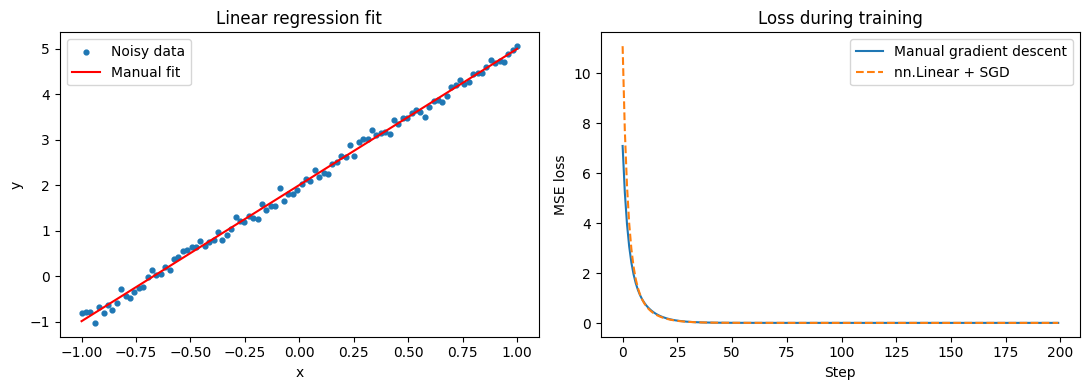

In [6]:
set_seed()
x_data = torch.linspace(-1, 1, 100).unsqueeze(1)
y_data = 3 * x_data + 2 + 0.1 * torch.randn_like(x_data)

weight = torch.zeros(1, requires_grad=True)
bias = torch.zeros(1, requires_grad=True)
learning_rate = 0.1
manual_losses = []

for step in range(200):
    predictions = x_data * weight + bias
    loss = ((predictions - y_data) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        weight -= learning_rate * weight.grad
        bias -= learning_rate * bias.grad
    weight.grad.zero_()
    bias.grad.zero_()
    manual_losses.append(loss.item())

print(f"Manual gradient descent: w = {weight.item():.3f}, b = {bias.item():.3f}")

linear_model = nn.Linear(1, 1)
sgd_optimizer = torch.optim.SGD(linear_model.parameters(), lr=0.1)
mse_loss = nn.MSELoss()
module_losses = []

for step in range(200):
    loss = mse_loss(linear_model(x_data), y_data)
    sgd_optimizer.zero_grad()
    loss.backward()
    sgd_optimizer.step()
    module_losses.append(loss.item())

print(f"nn.Linear with SGD:      w = {linear_model.weight.item():.3f}, b = {linear_model.bias.item():.3f}")
print("True values:             w = 3.000, b = 2.000")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x_data.numpy(), y_data.numpy(), s=12, label="Noisy data")
axes[0].plot(x_data.numpy(), (x_data * weight + bias).detach().numpy(), color="red", label="Manual fit")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Linear regression fit")
axes[0].legend()
axes[1].plot(manual_losses, label="Manual gradient descent")
axes[1].plot(module_losses, linestyle="--", label="nn.Linear + SGD")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("MSE loss")
axes[1].set_title("Loss during training")
axes[1].legend()
fig.tight_layout()
plt.show()

A **multi-layer perceptron** stacks fully connected (`nn.Linear`) layers separated by non-linear activation functions such as ReLU. Without the non-linearity, any stack of linear layers would collapse into a single linear map.

For the digits dataset:

1. `nn.Flatten` turns each `(1, 8, 8)` image into a vector of 64 values.
2. Hidden layers learn progressively more abstract features.
3. The output layer produces 10 **logits**, one per digit.
4. **Cross-entropy loss** applies softmax internally and compares the predicted distribution with the true label:

$$L = -\log \frac{e^{z_y}}{\sum_j e^{z_j}}$$

Training uses mini-batches and the **Adam** optimizer, which adapts the learning rate for every parameter. The validation set is evaluated after every epoch and the test set only once at the end.

In [7]:
set_seed()
train_loader = make_loader(*splits["train"], batch_size=64, shuffle=True)
val_loader = make_loader(*splits["val"], batch_size=128)
test_loader = make_loader(*splits["test"], batch_size=128)

mlp_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(64, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
).to(device)

print(mlp_model)
sample_inputs, sample_targets = next(iter(train_loader))
sample_logits = mlp_model(sample_inputs.to(device))
print("Input batch shape:", tuple(sample_inputs.shape))
print("Output logits shape:", tuple(sample_logits.shape))
print("Number of parameters:", count_parameters(mlp_model))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=64, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=10, bias=True)
)
Input batch shape: (64, 1, 8, 8)
Output logits shape: (64, 10)
Number of parameters: 17226


Final training accuracy:   0.9870
Final validation accuracy: 0.9666


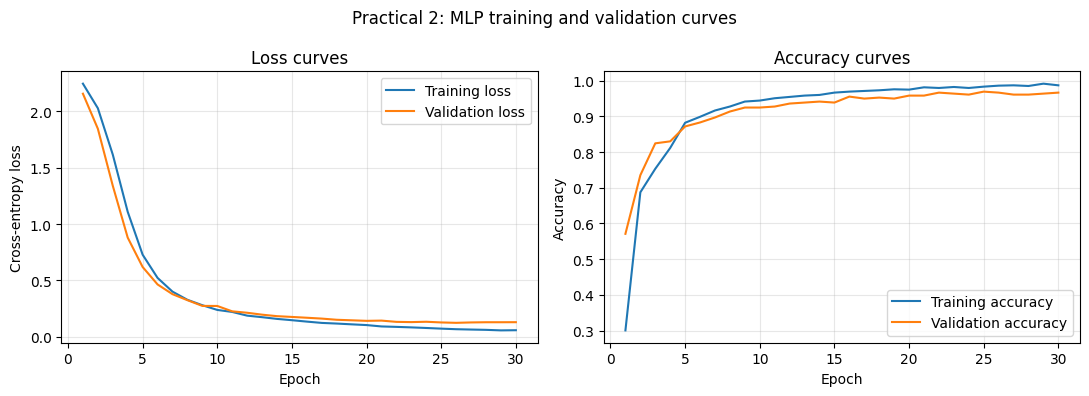

In [8]:
mlp_history = fit(mlp_model, train_loader, val_loader, epochs=30, lr=1e-3)

print(f"Final training accuracy:   {mlp_history['train_acc'][-1]:.4f}")
print(f"Final validation accuracy: {mlp_history['val_acc'][-1]:.4f}")
plot_history(mlp_history, "Practical 2: MLP training and validation curves")

MLP test accuracy: 0.9611


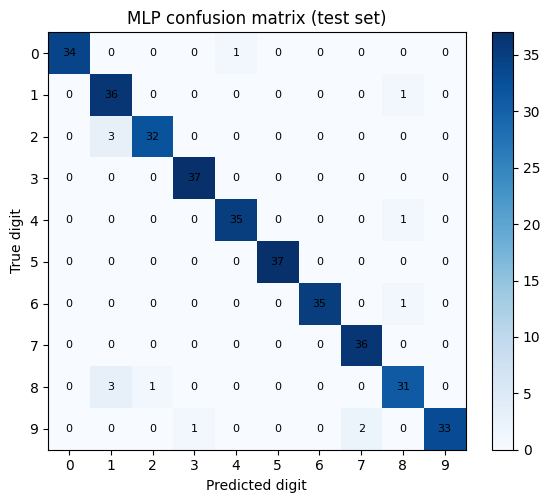

In [9]:
mlp_predictions, mlp_targets = predict_all(mlp_model, test_loader)
mlp_test_accuracy = (mlp_predictions == mlp_targets).mean()
print(f"MLP test accuracy: {mlp_test_accuracy:.4f}")

mlp_confusion = confusion_matrix(mlp_targets, mlp_predictions)
fig, axis = plt.subplots(figsize=(6, 5))
image_handle = axis.imshow(mlp_confusion, cmap="Blues")
axis.set_xticks(range(10))
axis.set_yticks(range(10))
axis.set_xlabel("Predicted digit")
axis.set_ylabel("True digit")
axis.set_title("MLP confusion matrix (test set)")
for row in range(10):
    for column in range(10):
        axis.text(column, row, mlp_confusion[row, column], ha="center", va="center", fontsize=8)
fig.colorbar(image_handle)
fig.tight_layout()
plt.show()

Fully connected layers ignore the spatial layout of an image. A **convolutional layer** instead slides small learnable filters (kernels) across the image, which gives two valuable properties:

- **Local connectivity:** each output value depends only on a small neighbourhood of pixels.
- **Weight sharing:** the same filter is applied at every position, so the number of parameters is small and the detected pattern (an edge, a curve) is found anywhere in the image.

The main building blocks are:

- `nn.Conv2d(in_channels, out_channels, kernel_size, padding)` creates feature maps.
- `nn.ReLU` adds non-linearity.
- `nn.MaxPool2d(2)` halves the height and width, keeping the strongest response and adding tolerance to small shifts.

With a 3 x 3 kernel and padding 1, the spatial size is preserved by convolution. The shapes in this network are:

`(1, 8, 8)` → Conv(16) → `(16, 8, 8)` → Pool → `(16, 4, 4)` → Conv(32) → `(32, 4, 4)` → Pool → `(32, 2, 2)` → Flatten → `128` → Linear → `10`

In [10]:
class DigitCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 2 * 2, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, inputs):
        return self.classifier(self.features(inputs))


set_seed()
cnn_model = DigitCNN().to(device)

probe = torch.zeros(4, 1, 8, 8, device=device)
print("Input shape:", tuple(probe.shape))
print("After features:", tuple(cnn_model.features(probe).shape))
print("Output logits shape:", tuple(cnn_model(probe).shape))
print("CNN parameters:", count_parameters(cnn_model))
print("MLP parameters:", count_parameters(mlp_model))

Input shape: (4, 1, 8, 8)
After features: (4, 32, 2, 2)
Output logits shape: (4, 10)
CNN parameters: 13706
MLP parameters: 17226


Final training accuracy:   0.9861
Final validation accuracy: 0.9582
CNN test accuracy: 0.9500
MLP test accuracy: 0.9611


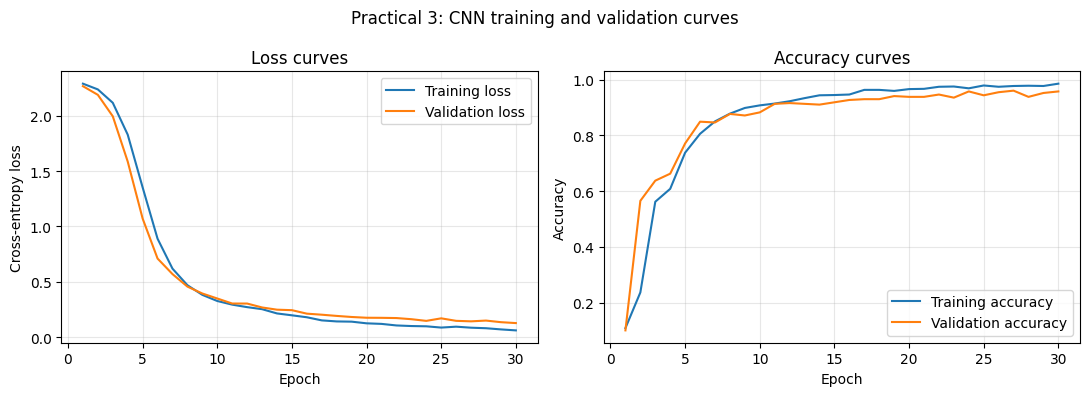

In [11]:
set_seed()
cnn_history = fit(cnn_model, train_loader, val_loader, epochs=30, lr=1e-3)

cnn_predictions, cnn_targets = predict_all(cnn_model, test_loader)
cnn_test_accuracy = (cnn_predictions == cnn_targets).mean()

print(f"Final training accuracy:   {cnn_history['train_acc'][-1]:.4f}")
print(f"Final validation accuracy: {cnn_history['val_acc'][-1]:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.4f}")
print(f"MLP test accuracy: {mlp_test_accuracy:.4f}")
plot_history(cnn_history, "Practical 3: CNN training and validation curves")

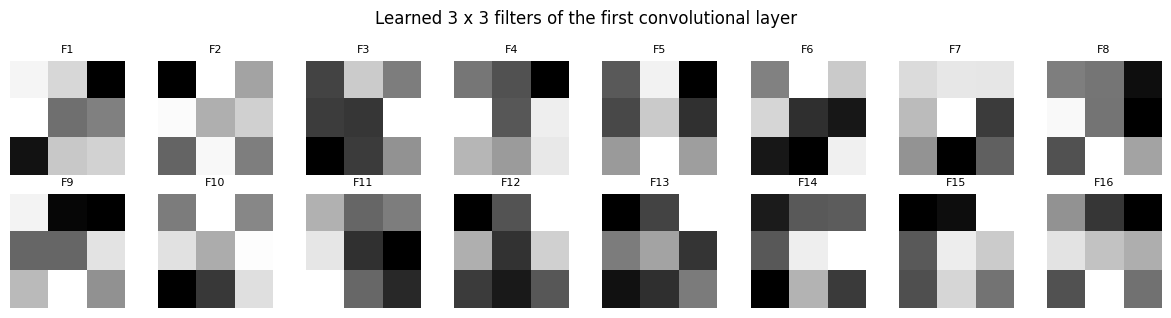

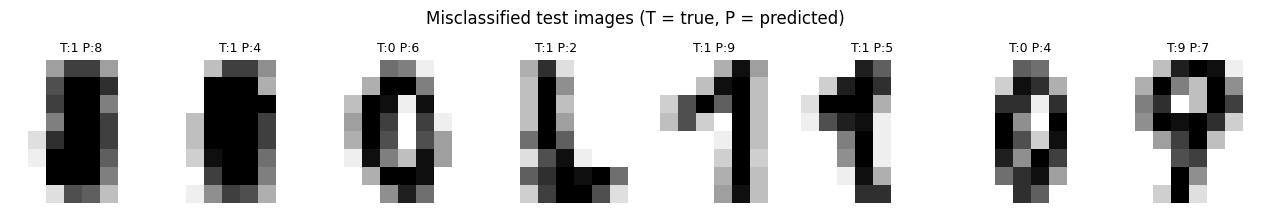

In [12]:
first_layer_filters = cnn_model.features[0].weight.detach().cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for index, axis in enumerate(axes.flat):
    axis.imshow(first_layer_filters[index, 0], cmap="gray")
    axis.set_title(f"F{index + 1}", fontsize=8)
    axis.axis("off")
fig.suptitle("Learned 3 x 3 filters of the first convolutional layer")
fig.tight_layout()
plt.show()

wrong_mask = cnn_predictions != cnn_targets
wrong_indices = np.where(wrong_mask)[0][:8]
test_images = splits["test"][0]
if len(wrong_indices) > 0:
    fig, axes = plt.subplots(1, len(wrong_indices), figsize=(1.6 * len(wrong_indices), 2.2))
    axes = np.atleast_1d(axes)
    for axis, sample_index in zip(axes, wrong_indices):
        axis.imshow(test_images[sample_index, 0], cmap="gray_r")
        axis.set_title(f"T:{cnn_targets[sample_index]} P:{cnn_predictions[sample_index]}", fontsize=9)
        axis.axis("off")
    fig.suptitle("Misclassified test images (T = true, P = predicted)")
    fig.tight_layout()
    plt.show()
else:
    print("The CNN made no mistakes on the test set.")

**Generalization** is a model's ability to perform well on data it has never seen. **Overfitting** happens when a model fits the noise and quirks of the training set instead of the underlying pattern. The typical signature is that *training loss keeps falling while validation loss stops improving or starts rising*. It is most likely when the model has many parameters compared with the amount of training data.

**Regularization** is any technique that reduces overfitting. This practical demonstrates three of them:

- **Dropout (`nn.Dropout`)** randomly sets a fraction $p$ of activations to zero in every training step and rescales the rest by $1/(1-p)$. The network cannot depend on any single neuron, which behaves like training an ensemble of thinner networks. Dropout is active only in `model.train()` mode and is disabled in `model.eval()` mode.
- **Batch normalization (`nn.BatchNorm1d`)** normalizes each feature over the mini-batch to zero mean and unit variance and then applies a learnable scale and shift. It stabilizes and speeds up training, and its batch-dependent noise has a mild regularizing effect.
- **Early stopping** monitors the validation loss and stops training when it has not improved for a number of epochs called the **patience**. The weights from the best epoch are then restored.

To make overfitting visible, the models below are trained on only **150 training samples**, while the validation and test sets keep their full size.

In [13]:
dropout_layer = nn.Dropout(p=0.5)
ones_vector = torch.ones(1, 10)

dropout_layer.train()
print("Dropout in train mode:", dropout_layer(ones_vector))
dropout_layer.eval()
print("Dropout in eval mode: ", dropout_layer(ones_vector))

set_seed()
raw_features = torch.randn(256, 4) * 3.0 + 5.0
normalized_features = nn.BatchNorm1d(4).train()(raw_features)
print("Before batch norm - mean:", raw_features.mean(dim=0).detach().numpy().round(2),
      "std:", raw_features.std(dim=0).detach().numpy().round(2))
print("After batch norm  - mean:", normalized_features.mean(dim=0).detach().numpy().round(2),
      "std:", normalized_features.std(dim=0).detach().numpy().round(2))

Dropout in train mode: tensor([[2., 2., 2., 0., 0., 0., 2., 2., 2., 0.]])
Dropout in eval mode:  tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])
Before batch norm - mean: [4.99 4.97 4.87 5.27] std: [2.89 3.1  2.99 3.08]
After batch norm  - mean: [ 0. -0.  0.  0.] std: [1. 1. 1. 1.]


In [14]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.best_state = None
        self.best_epoch = 0
        self.counter = 0
        self.epoch = 0

    def step(self, val_loss, model):
        self.epoch += 1
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_epoch = self.epoch
            self.best_state = copy.deepcopy(model.state_dict())
            self.counter = 0
            return False
        self.counter += 1
        return self.counter >= self.patience

    def restore(self, model):
        if self.best_state is not None:
            model.load_state_dict(self.best_state)


def build_mlp(dropout_rate=0.0, use_batch_norm=False, hidden_units=256):
    layers = [nn.Flatten()]
    in_features = 64
    for _ in range(2):
        layers.append(nn.Linear(in_features, hidden_units))
        if use_batch_norm:
            layers.append(nn.BatchNorm1d(hidden_units))
        layers.append(nn.ReLU())
        if dropout_rate > 0:
            layers.append(nn.Dropout(dropout_rate))
        in_features = hidden_units
    layers.append(nn.Linear(in_features, 10))
    return nn.Sequential(*layers)


small_train_inputs = splits["train"][0][:150]
small_train_targets = splits["train"][1][:150]
small_train_loader = make_loader(small_train_inputs, small_train_targets, batch_size=32, shuffle=True)
reg_val_loader = make_loader(*splits["val"], batch_size=128)
reg_test_loader = make_loader(*splits["test"], batch_size=128)

experiments = {
    "Baseline": dict(dropout_rate=0.0, use_batch_norm=False, early_stopping=False),
    "Dropout": dict(dropout_rate=0.5, use_batch_norm=False, early_stopping=False),
    "BatchNorm": dict(dropout_rate=0.0, use_batch_norm=True, early_stopping=False),
    "Baseline + EarlyStop": dict(dropout_rate=0.0, use_batch_norm=False, early_stopping=True),
    "Dropout + BN + EarlyStop": dict(dropout_rate=0.3, use_batch_norm=True, early_stopping=True),
}

print("Training samples used:", len(small_train_targets))
print("Example architecture:")
print(build_mlp(dropout_rate=0.3, use_batch_norm=True))

Training samples used: 150
Example architecture:
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=64, out_features=256, bias=True)
  (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (3): ReLU()
  (4): Dropout(p=0.3, inplace=False)
  (5): Linear(in_features=256, out_features=256, bias=True)
  (6): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (7): ReLU()
  (8): Dropout(p=0.3, inplace=False)
  (9): Linear(in_features=256, out_features=10, bias=True)
)


In [15]:
reg_results = {}
criterion = nn.CrossEntropyLoss()

for experiment_name, config in experiments.items():
    set_seed()
    model = build_mlp(config["dropout_rate"], config["use_batch_norm"]).to(device)
    stopper = EarlyStopping(patience=10) if config["early_stopping"] else None
    print(f"Training: {experiment_name}")
    history = fit(model, small_train_loader, reg_val_loader, epochs=100, lr=1e-3, early_stopper=stopper)
    test_loss, test_accuracy = run_epoch(model, reg_test_loader, criterion)
    reg_results[experiment_name] = {
        "history": history,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "epochs_run": len(history["train_loss"]),
        "best_epoch": int(np.argmin(history["val_loss"])) + 1,
    }

print("Finished all experiments.")

Training: Baseline
Training: Dropout
Training: BatchNorm
Training: Baseline + EarlyStop
Early stopping triggered at epoch 30; best epoch was 20.
Training: Dropout + BN + EarlyStop
Early stopping triggered at epoch 32; best epoch was 22.
Finished all experiments.


Model                         Epochs  BestEp  TrainAcc   ValAcc  TestAcc  MinValLoss
Baseline                         100      23     1.000    0.900    0.875      0.3731
Dropout                          100      64     1.000    0.903    0.878      0.3490
BatchNorm                        100      32     1.000    0.897    0.900      0.2958
Baseline + EarlyStop              30      20     1.000    0.900    0.875      0.3791
Dropout + BN + EarlyStop          32      22     1.000    0.900    0.892      0.3062


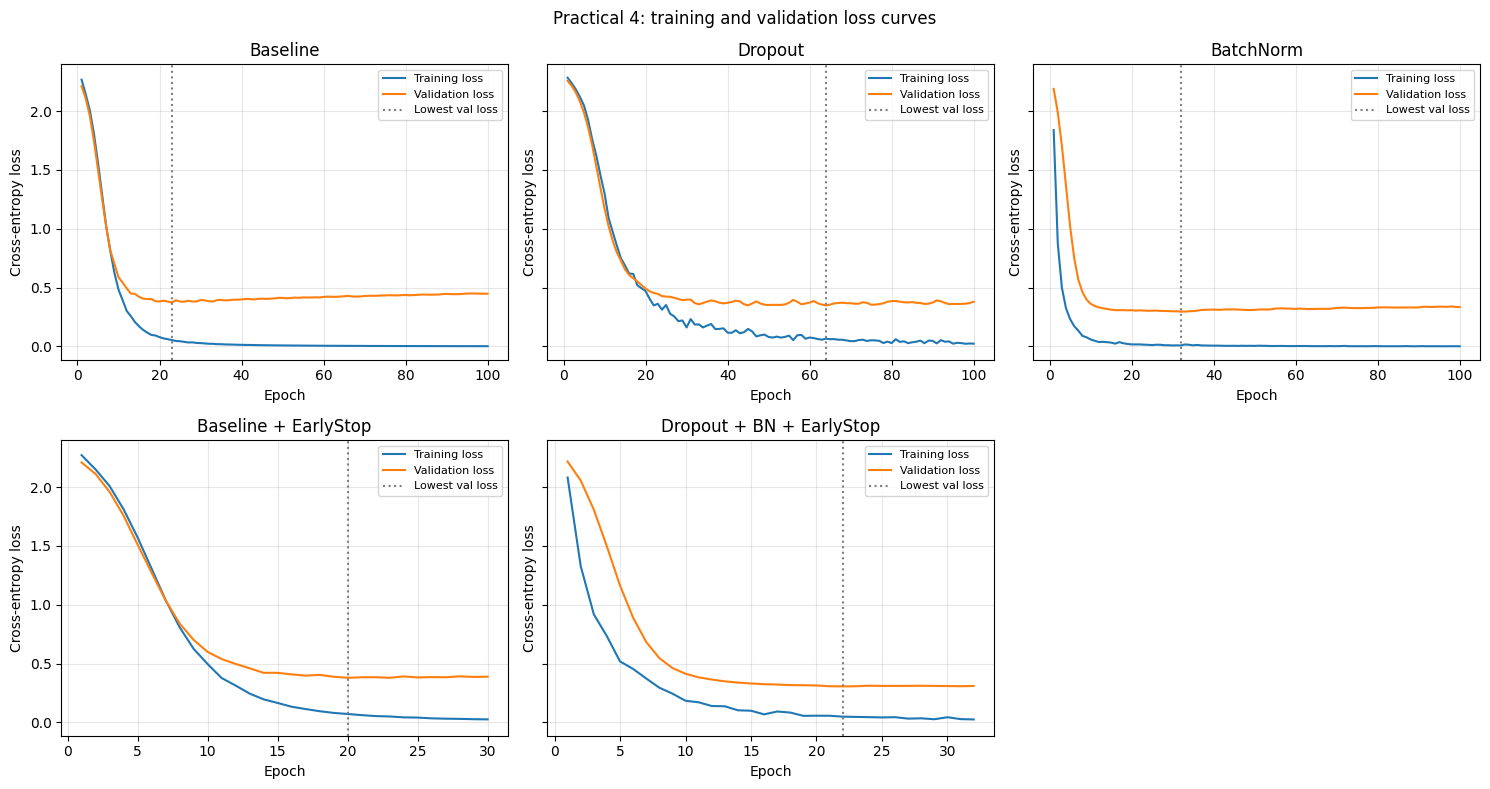

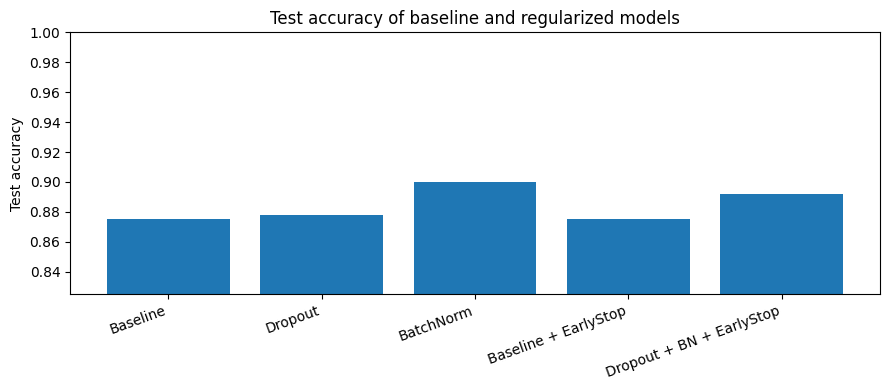

In [16]:
print(f"{'Model':28s}{'Epochs':>8s}{'BestEp':>8s}{'TrainAcc':>10s}{'ValAcc':>9s}{'TestAcc':>9s}{'MinValLoss':>12s}")
for experiment_name, outcome in reg_results.items():
    history = outcome["history"]
    print(
        f"{experiment_name:28s}{outcome['epochs_run']:8d}{outcome['best_epoch']:8d}"
        f"{history['train_acc'][-1]:10.3f}{history['val_acc'][-1]:9.3f}"
        f"{outcome['test_accuracy']:9.3f}{min(history['val_loss']):12.4f}"
    )

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for axis, (experiment_name, outcome) in zip(axes.flat, reg_results.items()):
    epochs = range(1, outcome["epochs_run"] + 1)
    axis.plot(epochs, outcome["history"]["train_loss"], label="Training loss")
    axis.plot(epochs, outcome["history"]["val_loss"], label="Validation loss")
    axis.axvline(outcome["best_epoch"], color="gray", linestyle=":", label="Lowest val loss")
    axis.set_title(experiment_name)
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Cross-entropy loss")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Practical 4: training and validation loss curves")
fig.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(9, 4))
names = list(reg_results.keys())
test_scores = [reg_results[name]["test_accuracy"] for name in names]
axis.bar(range(len(names)), test_scores)
axis.set_xticks(range(len(names)))
axis.set_xticklabels(names, rotation=20, ha="right")
axis.set_ylabel("Test accuracy")
axis.set_ylim(min(test_scores) - 0.05, 1.0)
axis.set_title("Test accuracy of baseline and regularized models")
fig.tight_layout()
plt.show()

In [17]:
for experiment_name, outcome in reg_results.items():
    history = outcome["history"]
    train_val_gap = history["train_acc"][-1] - history["val_acc"][-1]
    loss_rise = history["val_loss"][-1] - min(history["val_loss"])
    print(
        f"{experiment_name:28s} train-val accuracy gap: {train_val_gap:+.3f}   "
        f"val loss above its minimum at the last epoch: {loss_rise:+.4f}"
    )

Baseline                     train-val accuracy gap: +0.100   val loss above its minimum at the last epoch: +0.0749
Dropout                      train-val accuracy gap: +0.097   val loss above its minimum at the last epoch: +0.0307
BatchNorm                    train-val accuracy gap: +0.103   val loss above its minimum at the last epoch: +0.0388
Baseline + EarlyStop         train-val accuracy gap: +0.100   val loss above its minimum at the last epoch: +0.0093
Dropout + BN + EarlyStop     train-val accuracy gap: +0.100   val loss above its minimum at the last epoch: +0.0039


**Transfer learning** reuses knowledge learned on a large source task for a smaller target task. A CNN pretrained on ImageNet (1.2 million images, 1,000 classes) has learned general visual features: early layers detect edges and textures, middle layers detect parts, and deeper layers detect object-level patterns. These features are useful for many other image tasks, so we need far less data and computation than training from scratch.

**MobileNetV3 Small** is a lightweight pretrained CNN, built from depthwise-separable convolutions, designed for mobile devices. In `torchvision` its structure is:

- `features`: the convolutional **backbone** that extracts a feature map.
- `avgpool`: global average pooling that produces a 576-dimensional vector.
- `classifier`: the **head**, `Linear(576, 1024) → Hardswish → Dropout → Linear(1024, 1000)`.

The standard recipe is:

1. Load the pretrained network.
2. Replace the last layer so that it outputs the number of classes of the new task (10 here).
3. **Freeze** the backbone by setting `requires_grad=False` so its weights do not change.
4. Train only the classification head.

The backbone also contains batch normalization layers, so it is kept in `eval()` mode during training so that their running statistics stay frozen as well.

**Target task.** The digits images are upscaled from 8 x 8 to 64 x 64, repeated into 3 channels and normalized with the ImageNet mean and standard deviation. This is a deliberately small task that runs on a CPU. Digits are very different from natural photographs, so this practical illustrates the *mechanics* of transfer learning rather than being an ideal use case.

**Pretrained weights are downloaded from the internet** on first use. If the download fails, the code below falls back to a randomly initialised backbone and states this clearly. In that case the results are **not** transfer learning results.

In [18]:
from torchvision import models
from torchvision.models import MobileNet_V3_Small_Weights


def load_mobilenet_v3_small():
    try:
        model = models.mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
        print("Pretrained ImageNet weights loaded successfully.")
        return model, True
    except Exception as error:
        print("Could not load pretrained weights:", type(error).__name__, "-", error)
        print("Check your internet connection or download the weights manually.")
        print("Falling back to a RANDOMLY INITIALISED MobileNetV3 Small.")
        print("Results below will NOT demonstrate transfer learning.")
        return models.mobilenet_v3_small(weights=None), False


set_seed()
transfer_model, PRETRAINED_LOADED = load_mobilenet_v3_small()
MODEL_MODE = "pretrained backbone" if PRETRAINED_LOADED else "RANDOM backbone (weights unavailable)"
print("Backbone mode:", MODEL_MODE)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 52.5MB/s]

Pretrained ImageNet weights loaded successfully.
Backbone mode: pretrained backbone


In [19]:
NUM_CLASSES = 10

for parameter in transfer_model.features.parameters():
    parameter.requires_grad = False

head_in_features = transfer_model.classifier[3].in_features
transfer_model.classifier[3] = nn.Linear(head_in_features, NUM_CLASSES)
transfer_model = transfer_model.to(device)

print("Classifier head:")
print(transfer_model.classifier)
print("Total parameters:    ", count_parameters(transfer_model))
print("Trainable parameters:", count_trainable_parameters(transfer_model))
print("Frozen parameters:   ", count_parameters(transfer_model) - count_trainable_parameters(transfer_model))

imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
imagenet_std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def prepare_batch(images):
    resized = F.interpolate(images, size=(64, 64), mode="bilinear", align_corners=False)
    rgb_images = resized.repeat(1, 3, 1, 1)
    mean = imagenet_mean.to(images.device)
    std = imagenet_std.to(images.device)
    return (rgb_images - mean) / std


probe_batch = prepare_batch(splits["train"][0][:4].to(device))
print("Prepared input shape:", tuple(probe_batch.shape))
with torch.no_grad():
    transfer_model.eval()
    print("Output logits shape:", tuple(transfer_model(probe_batch).shape))

Classifier head:
Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=10, bias=True)
)
Total parameters:     1528106
Trainable parameters: 601098
Frozen parameters:    927008
Prepared input shape: (4, 3, 64, 64)
Output logits shape: (4, 10)


Epoch 1: train loss 1.3958, train acc 0.547, val loss 0.8618, val acc 0.724
Epoch 2: train loss 0.6725, train acc 0.798, val loss 0.5879, val acc 0.802
Epoch 3: train loss 0.4788, train acc 0.858, val loss 0.4740, val acc 0.844
Epoch 4: train loss 0.3791, train acc 0.891, val loss 0.4037, val acc 0.864
Epoch 5: train loss 0.3106, train acc 0.913, val loss 0.3810, val acc 0.869


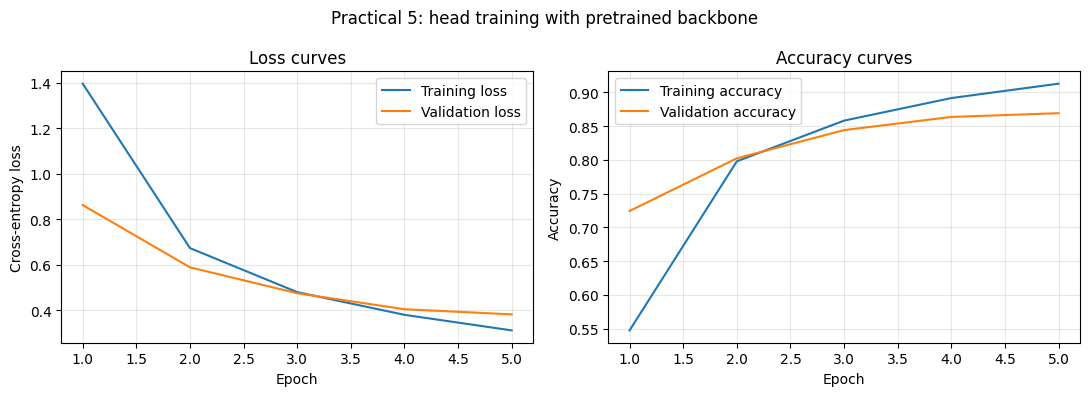

In [20]:
def run_transfer_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.eval()
    model.classifier.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for batch_inputs, batch_targets in loader:
            batch_inputs = prepare_batch(batch_inputs.to(device))
            batch_targets = batch_targets.to(device)
            logits = model(batch_inputs)
            loss = criterion(logits, batch_targets)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * batch_inputs.size(0)
            correct += (logits.argmax(dim=1) == batch_targets).sum().item()
            count += batch_inputs.size(0)
    return total_loss / count, correct / count


set_seed()
transfer_train_loader = make_loader(*splits["train"], batch_size=64, shuffle=True)
transfer_val_loader = make_loader(*splits["val"], batch_size=128)
transfer_test_loader = make_loader(*splits["test"], batch_size=128)

transfer_criterion = nn.CrossEntropyLoss()
transfer_optimizer = torch.optim.Adam(transfer_model.classifier.parameters(), lr=1e-3)
transfer_history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(1, 6):
    train_loss, train_acc = run_transfer_epoch(transfer_model, transfer_train_loader, transfer_criterion, transfer_optimizer)
    val_loss, val_acc = run_transfer_epoch(transfer_model, transfer_val_loader, transfer_criterion)
    transfer_history["train_loss"].append(train_loss)
    transfer_history["val_loss"].append(val_loss)
    transfer_history["train_acc"].append(train_acc)
    transfer_history["val_acc"].append(val_acc)
    print(f"Epoch {epoch}: train loss {train_loss:.4f}, train acc {train_acc:.3f}, val loss {val_loss:.4f}, val acc {val_acc:.3f}")

plot_history(transfer_history, f"Practical 5: head training with {MODEL_MODE}")

Backbone mode: pretrained backbone
Test accuracy of the trained head: 0.8889


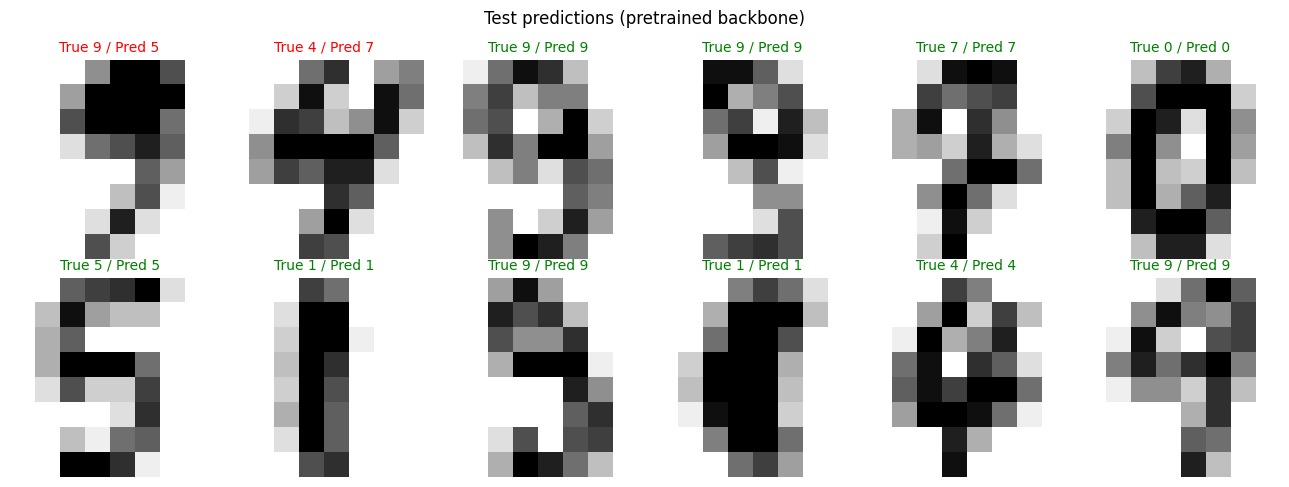

In [21]:
transfer_predictions, transfer_targets = predict_all(transfer_model, transfer_test_loader, transform=prepare_batch)
transfer_test_accuracy = (transfer_predictions == transfer_targets).mean()
print(f"Backbone mode: {MODEL_MODE}")
print(f"Test accuracy of the trained head: {transfer_test_accuracy:.4f}")
if not PRETRAINED_LOADED:
    print("WARNING: pretrained weights were unavailable, so this is NOT a transfer learning result.")

test_images = splits["test"][0]
sample_count = 12
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for axis, sample_index in zip(axes.flat, range(sample_count)):
    axis.imshow(test_images[sample_index, 0], cmap="gray_r")
    is_correct = transfer_predictions[sample_index] == transfer_targets[sample_index]
    axis.set_title(
        f"True {transfer_targets[sample_index]} / Pred {transfer_predictions[sample_index]}",
        color="green" if is_correct else "red",
        fontsize=10,
    )
    axis.axis("off")
fig.suptitle(f"Test predictions ({MODEL_MODE})")
fig.tight_layout()
plt.show()

The **Transformer** architecture replaces recurrence with **self-attention**, in which every token compares itself with every other token and builds a context-aware representation. Pretrained Transformers such as BERT and its smaller, faster distilled version **DistilBERT** are trained on huge text corpora and can then be fine-tuned for specific tasks.

The **Hugging Face Transformers** library gives a unified interface to thousands of pretrained models. The main pieces are:

- **Tokenizer** converts text into token ids (sub-word units) with padding and attention masks.
- **Model** maps token ids to hidden states or, for classification models, to logits.
- **`pipeline`** bundles tokenizer, model and post-processing into one call, for example `pipeline("sentiment-analysis")`.

The model used here is `distilbert-base-uncased-finetuned-sst-2-english`, which was fine-tuned on the SST-2 movie review sentiment dataset and predicts `POSITIVE` or `NEGATIVE`. The confidence score is the softmax probability of the predicted label.


In [22]:
TRANSFORMERS_AVAILABLE = importlib.util.find_spec("transformers") is not None
SENTIMENT_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"

sample_sentences = [
    "I absolutely loved this movie, the acting was brilliant.",
    "The service was terrible and the food arrived cold.",
    "The package arrived on Tuesday.",
    "What a wonderful day to learn about deep learning!",
    "I am disappointed with the quality of this product.",
    "The new update made the app faster and much easier to use.",
]

print("transformers installed:", TRANSFORMERS_AVAILABLE)
if not TRANSFORMERS_AVAILABLE:
    print("Install it with: pip install transformers")

transformers installed: True


In [23]:
sentiment_results = []

if TRANSFORMERS_AVAILABLE:
    try:
        from transformers import pipeline

        sentiment_pipeline = pipeline("sentiment-analysis", model=SENTIMENT_MODEL)
        raw_outputs = sentiment_pipeline(sample_sentences)
        for sentence, output in zip(sample_sentences, raw_outputs):
            sentiment_results.append((sentence, output["label"], output["score"]))
    except Exception as error:
        print("Could not load or run the sentiment pipeline:", type(error).__name__, "-", error)
        print("This usually means there is no internet access for the first download.")
else:
    print("Skipping: the transformers package is not installed.")

if sentiment_results:
    print(f"{'Label':10s}{'Confidence':>12s}   Text")
    for sentence, label, score in sentiment_results:
        print(f"{label:10s}{score:12.4f}   {sentence}")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Label       Confidence   Text
POSITIVE        0.9999   I absolutely loved this movie, the acting was brilliant.
NEGATIVE        0.9997   The service was terrible and the food arrived cold.
POSITIVE        0.9830   The package arrived on Tuesday.
POSITIVE        0.9999   What a wonderful day to learn about deep learning!
NEGATIVE        0.9998   I am disappointed with the quality of this product.
POSITIVE        0.9941   The new update made the app faster and much easier to use.


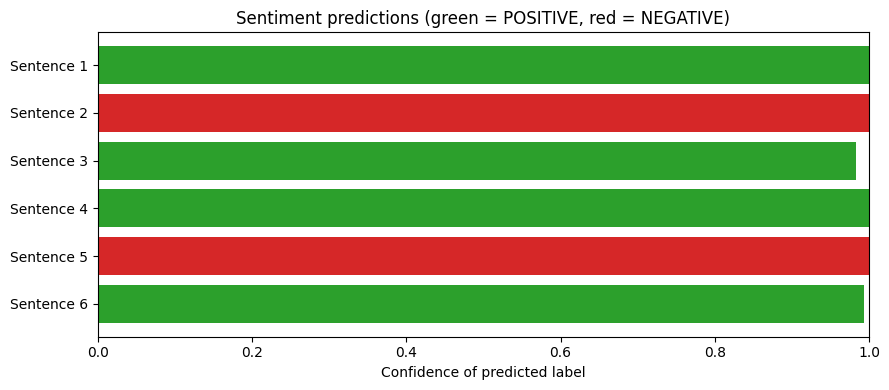

In [24]:
if sentiment_results:
    fig, axis = plt.subplots(figsize=(9, 4))
    bar_colors = ["tab:green" if label == "POSITIVE" else "tab:red" for _, label, _ in sentiment_results]
    axis.barh(range(len(sentiment_results)), [score for _, _, score in sentiment_results], color=bar_colors)
    axis.set_yticks(range(len(sentiment_results)))
    axis.set_yticklabels([f"Sentence {index + 1}" for index in range(len(sentiment_results))])
    axis.set_xlim(0, 1)
    axis.set_xlabel("Confidence of predicted label")
    axis.set_title("Sentiment predictions (green = POSITIVE, red = NEGATIVE)")
    axis.invert_yaxis()
    fig.tight_layout()
    plt.show()
else:
    print("No sentiment results available to plot.")

In [25]:
if TRANSFORMERS_AVAILABLE:
    try:
        from transformers import AutoModelForSequenceClassification, AutoTokenizer

        sentiment_tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL)
        sentiment_model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL)
        sentiment_model.eval()

        batch_sentences = sample_sentences[:3]
        encoded_batch = sentiment_tokenizer(batch_sentences, padding=True, truncation=True, return_tensors="pt")
        print("input_ids shape:", tuple(encoded_batch["input_ids"].shape))
        print("Tokens of sentence 1:", sentiment_tokenizer.convert_ids_to_tokens(encoded_batch["input_ids"][0]))

        with torch.no_grad():
            logits = sentiment_model(**encoded_batch).logits
        probabilities = F.softmax(logits, dim=-1)
        print("logits shape:", tuple(logits.shape))

        for sentence, row in zip(batch_sentences, probabilities):
            predicted_index = int(row.argmax())
            print(f"{sentiment_model.config.id2label[predicted_index]:10s}{row[predicted_index].item():.4f}   {sentence}")
    except Exception as error:
        print("Could not run the manual tokenizer and model example:", type(error).__name__, "-", error)
else:
    print("Skipping: the transformers package is not installed.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

input_ids shape: (3, 13)
Tokens of sentence 1: ['[CLS]', 'i', 'absolutely', 'loved', 'this', 'movie', ',', 'the', 'acting', 'was', 'brilliant', '.', '[SEP]']
logits shape: (3, 2)
POSITIVE  0.9999   I absolutely loved this movie, the acting was brilliant.
NEGATIVE  0.9997   The service was terrible and the food arrived cold.
POSITIVE  0.9830   The package arrived on Tuesday.


**Large language models** are very large Transformer networks trained to predict the next token on enormous text collections. After additional instruction tuning, they can follow natural-language instructions. Typical applications include:

- **Text generation**: drafting emails, code or stories.
- **Summarization**: condensing long documents.
- **Question answering**: answering from knowledge or from supplied context.
- Translation, information extraction, classification, tutoring and chat assistants.

### Hosted APIs versus local open models

| Aspect | Hosted API (OpenAI, Anthropic) | Local open model (Hugging Face, Ollama) |
|---|---|---|
| Quality | Usually the strongest models available | Smaller models, quality depends on size |
| Cost | Pay per token, requires an account and billing | Free to run after download, but uses your electricity and hardware |
| Hardware | None needed locally | Needs enough RAM or GPU memory for the model |
| Privacy | Prompts are sent to a third party | Data stays on your machine |
| Setup | API key and internet | Download model weights, optional server |
| Offline use | Not possible | Possible after the first download |
| Control | Provider decides model versions and limits | Full control over model, parameters and updates |

### Requirements

- **Hosted APIs:** `pip install openai anthropic`, an API key stored in an **environment variable** (`OPENAI_API_KEY` or `ANTHROPIC_API_KEY`), and internet access. Requests are billed, so **no call is made unless you explicitly switch on a flag** in the configuration cell.
- **Hugging Face local model:** `pip install transformers`, internet for the first download (the small `google/flan-t5-small` model is about 300 MB), and about 1 to 2 GB of RAM. A GPU is not required.
- **Ollama:** install it from the Ollama website, start the server, and run `ollama pull llama3.2` once. Small models need about 4 to 8 GB of RAM, and larger ones need more or a GPU.

### Setting API keys safely

Never write a key in the notebook. Set it in the environment before starting Jupyter, for example `export ANTHROPIC_API_KEY=...` on Linux or macOS, `setx ANTHROPIC_API_KEY ...` on Windows, or the Secrets panel in Google Colab. The code only reads `os.environ`. Model names can be changed with the `OPENAI_MODEL` and `ANTHROPIC_MODEL` environment variables if the defaults are retired.

In [26]:
import json
import os
import urllib.error
import urllib.request

RUN_ANTHROPIC = False
RUN_OPENAI = False
RUN_HUGGINGFACE_LOCAL = False
RUN_OLLAMA = False

ANTHROPIC_MODEL = os.environ.get("ANTHROPIC_MODEL", "claude-sonnet-5-5")
OPENAI_MODEL = os.environ.get("OPENAI_MODEL", "gpt-4o-mini")
OLLAMA_MODEL = os.environ.get("OLLAMA_MODEL", "llama3.2")
OLLAMA_URL = os.environ.get("OLLAMA_URL", "http://localhost:11434/api/generate")

article_text = (
    "Transfer learning reuses a neural network trained on a large dataset for a new task. "
    "Instead of training from scratch, practitioners freeze most pretrained layers and train a small new head. "
    "This reduces training time, lowers the amount of labelled data required and often improves accuracy."
)

llm_tasks = {
    "Text generation": "Write two sentences that explain what a neural network is to a school student.",
    "Summarization": "Summarize the following text in one sentence: " + article_text,
    "Question answering": "Using only this text, answer the question. Text: " + article_text + " Question: What does transfer learning reduce?",
}

print("Paid API calls are disabled by default.")
print("Set RUN_ANTHROPIC or RUN_OPENAI to True to enable them.")
print("ANTHROPIC_API_KEY found:", bool(os.environ.get("ANTHROPIC_API_KEY")))
print("OPENAI_API_KEY found:   ", bool(os.environ.get("OPENAI_API_KEY")))

Paid API calls are disabled by default.
Set RUN_ANTHROPIC or RUN_OPENAI to True to enable them.
ANTHROPIC_API_KEY found: False
OPENAI_API_KEY found:    False


In [27]:
def ask_anthropic(prompt, max_tokens=300):
    api_key = os.environ.get("ANTHROPIC_API_KEY")
    if not api_key:
        return None, "ANTHROPIC_API_KEY is not set."
    if importlib.util.find_spec("anthropic") is None:
        return None, "The anthropic package is not installed (pip install anthropic)."
    try:
        import anthropic

        client = anthropic.Anthropic(api_key=api_key)
        message = client.messages.create(
            model=ANTHROPIC_MODEL,
            max_tokens=max_tokens,
            messages=[{"role": "user", "content": prompt}],
        )
        return message.content[0].text, None
    except Exception as error:
        return None, f"{type(error).__name__}: {error}"


def ask_openai(prompt, max_tokens=300):
    api_key = os.environ.get("OPENAI_API_KEY")
    if not api_key:
        return None, "OPENAI_API_KEY is not set."
    if importlib.util.find_spec("openai") is None:
        return None, "The openai package is not installed (pip install openai)."
    try:
        from openai import OpenAI

        client = OpenAI(api_key=api_key)
        response = client.chat.completions.create(
            model=OPENAI_MODEL,
            max_completion_tokens=max_tokens,
            messages=[{"role": "user", "content": prompt}],
        )
        return response.choices[0].message.content, None
    except Exception as error:
        return None, f"{type(error).__name__}: {error}"


def run_provider(provider_name, enabled, ask_function):
    print("=" * 70)
    print(provider_name)
    print("=" * 70)
    if not enabled:
        print("Skipped: the run flag for this provider is False, so no paid call was made.")
        return
    for task_name, prompt in llm_tasks.items():
        answer, error_message = ask_function(prompt)
        print(f"[{task_name}]")
        print(answer if error_message is None else f"Could not complete the request. {error_message}")
        print()


print("API helper functions defined.")

API helper functions defined.


In [28]:
run_provider(f"Anthropic API ({ANTHROPIC_MODEL})", RUN_ANTHROPIC, ask_anthropic)
run_provider(f"OpenAI API ({OPENAI_MODEL})", RUN_OPENAI, ask_openai)

Anthropic API (claude-sonnet-5-5)
Skipped: the run flag for this provider is False, so no paid call was made.
OpenAI API (gpt-4o-mini)
Skipped: the run flag for this provider is False, so no paid call was made.


In [29]:
def run_huggingface_local():
    if not RUN_HUGGINGFACE_LOCAL:
        print("Skipped: RUN_HUGGINGFACE_LOCAL is False.")
        return
    if importlib.util.find_spec("transformers") is None:
        print("The transformers package is not installed (pip install transformers).")
        return
    try:
        from transformers import pipeline

        local_generator = pipeline("text2text-generation", model="google/flan-t5-small")
        for task_name, prompt in llm_tasks.items():
            output = local_generator(prompt, max_new_tokens=80)
            print(f"[{task_name}]")
            print(output[0]["generated_text"])
            print()
    except Exception as error:
        print("Could not load or run the local Hugging Face model:", type(error).__name__, "-", error)
        print("The first run needs internet access to download the model.")


run_huggingface_local()

Skipped: RUN_HUGGINGFACE_LOCAL is False.


In [30]:
def ask_ollama(prompt):
    request_body = json.dumps({"model": OLLAMA_MODEL, "prompt": prompt, "stream": False}).encode("utf-8")
    request = urllib.request.Request(OLLAMA_URL, data=request_body, headers={"Content-Type": "application/json"})
    try:
        with urllib.request.urlopen(request, timeout=120) as response:
            return json.loads(response.read().decode("utf-8")).get("response", ""), None
    except urllib.error.URLError as error:
        return None, f"Ollama server not reachable at {OLLAMA_URL} ({error.reason})."
    except Exception as error:
        return None, f"{type(error).__name__}: {error}"


run_provider(f"Ollama local model ({OLLAMA_MODEL})", RUN_OLLAMA, ask_ollama)

Ollama local model (llama3.2)
Skipped: the run flag for this provider is False, so no paid call was made.
